# TriggerNet Level 1 — Notebook 04: `hls4ml` FPGA Firmware & Bit-Accurate Check

## From PyTorch to Microsecond FPGA Circuits
A smaller PyTorch checkpoint is only half the story. To prove a neural network is genuinely **trigger-deployable**, we pass it into **`hls4ml`** — CERN/FastML's open-source compiler that translates neural networks into **C++ High-Level Synthesis (HLS)** hardware code for AMD/Xilinx FPGAs.

### Key FPGA Terms (2-Minute Crash Course)
- **LUT (Look-Up Table):** General-purpose programmable logic gates on an FPGA (used for additions, ReLU comparisons, routing, small multiplications).
- **DSP (Digital Signal Processor slice):** Dedicated fast hardware multiplier-accumulator circuits. **Pruning weights to `0`** directly saves DSPs!
- **BRAM (Block RAM):** On-chip SRAM memory storing weights/lookup tables.
- **`ap_fixed<W, I>`:** Xilinx Arbitrary Precision fixed-point C++ type (`W` total bits, `I` integer bits).
- **`Strategy = 'Latency'` & `ReuseFactor = 1`:**
  - `ReuseFactor = 1` means **fully unrolled**: every single non-zero weight gets its own parallel hardware multiplier so the entire neural network finishes in **tens of nanoseconds** (a handful of FPGA clock cycles at 200 MHz / 5 ns per cycle)!
  - Higher `ReuseFactor` (e.g. `4` or `8`) reuses each multiplier across multiple clock cycles — slightly slower latency, much smaller chip footprint.

### What This Notebook Does
1. Loads our compressed checkpoints (`QAT_8b_p50` and `QAT_6b_p75`) from Notebook 03.
2. Generates the **real C++ HLS firmware project** (`myproject.cpp`, `defines.h`, `parameters.h`, `weights/*.txt`) using `hls4ml.converters.convert_from_pytorch_model`.
3. Inspects the generated C++ headers & weight arrays directly (building your CERN C++ literacy organically!).
4. Runs **Bit-Accurate Hardware Verification** comparing PyTorch predictions against fixed-point hardware emulation:
   - If `g++` is installed on your machine, compiles and executes the actual `hls4ml` C++ shared library (`hls_model.compile()` + `hls_model.predict()`).
   - Even before `g++` is installed, runs an **exact `ap_fixed<W, I>` fixed-point layer-by-layer emulator** powered by `hls4ml`'s own `quantizers` library so you can verify bit-level agreement right away!

In [1]:
from pathlib import Path
import json
import shutil
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import hls4ml
from quantizers import get_fixed_quantizer_np

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import JetMLP, QuantizedJetMLP
from src.metrics import CLASS_NAMES, CLASS_LABELS, evaluate_jet_predictions

DATA_PATH = PROJECT_ROOT / "data" / "hls4ml_lhc_jets_hlf.npz"
CKPT_DIR = PROJECT_ROOT / "checkpoints"
FIG_DIR = PROJECT_ROOT / "figures"
RES_DIR = PROJECT_ROOT / "results"
HLS_OUT_DIR = PROJECT_ROOT / "hls_firmware"

data = np.load(DATA_PATH, allow_pickle=True)
X_test, y_test = data["X_test"], data["y_test"]

# Load Float32 baseline and our two compressed QAT+Pruned checkpoints
float_model = JetMLP()
float_model.load_state_dict(torch.load(CKPT_DIR / "float32_baseline.pt", map_location="cpu", weights_only=True))
float_model.eval()

ckpt_8b = torch.load(CKPT_DIR / "qat_8b_p50.pt", map_location="cpu", weights_only=False)
ckpt_6b = torch.load(CKPT_DIR / "qat_6b_p75.pt", map_location="cpu", weights_only=False)

def rebuild_sequential_from_ckpt(ckpt: dict) -> nn.Sequential:
    seq = nn.Sequential(
        nn.Linear(16, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, 32), nn.ReLU(),
        nn.Linear(32, 5),
    )
    seq.load_state_dict(ckpt["exported_state_dict"])
    seq.eval()
    return seq

def rebuild_qat_from_ckpt(ckpt: dict) -> QuantizedJetMLP:
    q = QuantizedJetMLP(
        weight_bits=ckpt["weight_bits"],
        weight_int_bits=ckpt["weight_int_bits"],
        act_bits=ckpt["act_bits"],
        act_int_bits=ckpt["act_int_bits"],
    )
    q.load_state_dict(ckpt["state_dict"])
    q.eval()
    return q

model_8b = rebuild_sequential_from_ckpt(ckpt_8b)
model_6b = rebuild_sequential_from_ckpt(ckpt_6b)
qat_8b = rebuild_qat_from_ckpt(ckpt_8b)
qat_6b = rebuild_qat_from_ckpt(ckpt_6b)

print(f"hls4ml version: {hls4ml.__version__}")
print(f"Loaded {ckpt_8b['tag']} -> sparsity={ckpt_8b['hardware']['sparsity']*100:.1f}%, BOPs={ckpt_8b['hardware']['effective_bops']:,}")
print(f"Loaded {ckpt_6b['tag']} -> sparsity={ckpt_6b['hardware']['sparsity']*100:.1f}%, BOPs={ckpt_6b['hardware']['effective_bops']:,}")

hls4ml version: 1.3.1
Loaded QAT_8b_p50 -> sparsity=50.0%, BOPs=136,192
Loaded QAT_6b_p75 -> sparsity=75.0%, BOPs=38,304


## 1. Convert Compressed PyTorch Model → C++ FPGA Firmware (`hls4ml`)
Notice how we explicitly configure per-layer fixed-point types in `hls_config`:
- Input features: `ap_fixed<16, 6>` (plenty of dynamic range for standardized jet features `[-8, +8]`).
- Dense weights & biases: `ap_fixed<W, I>` matching our QAT precision (`ap_fixed<8, 2>` or `ap_fixed<6, 2>`).
- Dense accumulators: `ap_fixed<16, 6>` (prevents overflow when summing 64 products inside a neuron!).
- ReLU activations: `ap_ufixed<W, I>` matching our unsigned QAT activations (`ap_ufixed<8, 3>` or `ap_ufixed<6, 3>`).
- `Strategy = 'Latency'`, `ReuseFactor = 1` for microsecond-scale fully parallel execution.

In [2]:
def convert_to_hls4ml(
    pytorch_seq: nn.Sequential,
    ckpt: dict,
    out_dir: Path,
    project_name: str,
) -> tuple[hls4ml.model.ModelGraph, dict]:
    wb, wi = ckpt["weight_bits"], ckpt["weight_int_bits"]
    ab, ai = ckpt["act_bits"], ckpt["act_int_bits"]

    hls_cfg = hls4ml.utils.config_from_pytorch_model(
        pytorch_seq,
        input_shape=(16,),
        granularity="name",
        default_precision="ap_fixed<16,6>",
        default_reuse_factor=1,
    )
    hls_cfg["Model"]["Strategy"] = "Latency"

    # Match exact fixed-point bit-widths learned during QAT
    for layer_name, layer_cfg in hls_cfg["LayerName"].items():
        if "Precision" not in layer_cfg:
            continue
        if layer_name in ("_0", "_2", "_4", "_6"):  # Linear layers
            layer_cfg["Precision"]["weight"] = f"ap_fixed<{wb},{wi}>"
            layer_cfg["Precision"]["bias"] = f"ap_fixed<{wb},{wi}>"
            layer_cfg["Precision"]["accum"] = "ap_fixed<16,6>"
            layer_cfg["Precision"]["result"] = "ap_fixed<16,6>"
        elif layer_name in ("_1", "_3", "_5"):      # ReLU layers
            layer_cfg["Precision"]["result"] = f"ap_ufixed<{ab},{ai}>"

    if out_dir.exists():
        shutil.rmtree(out_dir)

    hls_model = hls4ml.converters.convert_from_pytorch_model(
        pytorch_seq,
        output_dir=str(out_dir),
        project_name=project_name,
        input_shape=(16,),
        hls_config=hls_cfg,
        backend="Vivado",
    )
    hls_model.write()
    return hls_model, hls_cfg


hls_8b, cfg_8b = convert_to_hls4ml(model_8b, ckpt_8b, HLS_OUT_DIR / "triggernet_8b_p50", "triggernet_8b_p50")
hls_6b, cfg_6b = convert_to_hls4ml(model_6b, ckpt_6b, HLS_OUT_DIR / "triggernet_6b_p75", "triggernet_6b_p75")

print("\nGenerated FPGA firmware files for triggernet_6b_p75:")
fw_dir = HLS_OUT_DIR / "triggernet_6b_p75" / "firmware"
for p in sorted(fw_dir.iterdir()):
    print("  -", p.name)

Interpreting Model ...
Topology:
Layer name: _0, layer type: Dense, input shape: [[None, 16]]
Layer name: _1, layer type: Activation, input shape: [[None, 64]]
Layer name: _2, layer type: Dense, input shape: [[None, 64]]
Layer name: _3, layer type: Activation, input shape: [[None, 32]]
Layer name: _4, layer type: Dense, input shape: [[None, 32]]
Layer name: _5, layer type: Activation, input shape: [[None, 32]]
Layer name: _6, layer type: Dense, input shape: [[None, 32]]
Interpreting Model ...
Topology:
Layer name: _0, layer type: Dense, input shape: [[None, 16]]
Layer name: _1, layer type: Activation, input shape: [[None, 64]]
Layer name: _2, layer type: Dense, input shape: [[None, 64]]
Layer name: _3, layer type: Activation, input shape: [[None, 32]]
Layer name: _4, layer type: Dense, input shape: [[None, 32]]
Layer name: _5, layer type: Activation, input shape: [[None, 32]]
Layer name: _6, layer type: Dense, input shape: [[None, 32]]

Generated FPGA firmware files for triggernet_6b_p

## 2. Inspect the Generated C++ FPGA Firmware (Learn C++ / HLS by Reading Real Code!)
Let's inspect three generated files from `hls_firmware/triggernet_6b_p75/firmware/`:
1. **`defines.h`** — where `hls4ml` defines our exact fixed-point C++ types (`typedef ap_fixed<6,2> weight2_t;`, `typedef ap_ufixed<6,3> layer3_t;`).
2. **`myproject.cpp`** — the actual top-level hardware function with `#pragma HLS PIPELINE` and layer-by-layer calls (`nnet::dense`, `nnet::relu`).
3. **`weights/w2.txt`** — the quantized weight matrix baked into hardware ROM — notice how ~75% of the numbers are literally `0`!

In [3]:
fw_dir = HLS_OUT_DIR / "triggernet_6b_p75" / "firmware"

print("=== firmware/defines.h ===")
print((fw_dir / "defines.h").read_text())

print("=== firmware/triggernet_6b_p75.cpp ===")
print((fw_dir / "triggernet_6b_p75.cpp").read_text())

w_files = sorted((fw_dir / "weights").glob("w*.txt"))
if w_files:
    raw_txt = w_files[0].read_text().strip()
    vals = [float(v.strip()) for v in raw_txt.split(",") if v.strip()]
    zero_pct = 100.0 * sum(v == 0.0 for v in vals) / len(vals)
    print(f"=== {w_files[0].name} (First Layer Hardware Weights) ===")
    print(f"Total entries: {len(vals)} | Exact zeros baked into HLS weights: {zero_pct:.1f}%")
    print("First 24 weights:", vals[:24])

=== firmware/defines.h ===
#ifndef DEFINES_H_
#define DEFINES_H_

#include "ap_fixed.h"
#include "ap_int.h"
#include "nnet_utils/nnet_types.h"
#include <array>
#include <cstddef>
#include <cstdio>
#include <tuple>
#include <tuple>


// hls-fpga-machine-learning insert numbers

// hls-fpga-machine-learning insert layer-precision
typedef ap_fixed<16,6> input_t;
typedef ap_fixed<16,6> _0_accum_t;
typedef ap_fixed<16,6> layer2_t;
typedef ap_fixed<6,2> _0_weight_t;
typedef ap_fixed<6,2> _0_bias_t;
typedef ap_uint<1> layer2_index;
typedef ap_ufixed<6,3> layer3_t;
typedef ap_fixed<18,8> _1_table_t;
typedef ap_fixed<16,6> _2_accum_t;
typedef ap_fixed<16,6> layer4_t;
typedef ap_fixed<6,2> _2_weight_t;
typedef ap_fixed<6,2> _2_bias_t;
typedef ap_uint<1> layer4_index;
typedef ap_ufixed<6,3> layer5_t;
typedef ap_fixed<18,8> _3_table_t;
typedef ap_fixed<16,6> _4_accum_t;
typedef ap_fixed<16,6> layer6_t;
typedef ap_fixed<6,2> _4_weight_t;
typedef ap_fixed<6,2> _4_bias_t;
typedef ap_uint<1> layer6_in

## 3. Bit-Accurate Hardware Verification (PyTorch vs. Fixed-Point Firmware)
Now we run 20,000 test jets through:
1. **PyTorch Float32 Baseline** (original uncompressed reference),
2. **PyTorch QAT + Pruned (`6-bit, 75% pruned` & `8-bit, 50% pruned`)**, and
3. **Bit-Accurate Fixed-Point Hardware Execution**:
   - Uses compiled `hls4ml` C++ (`hls_model.compile()` → `hls_model.predict()`) automatically if `g++` is installed!
   - Otherwise uses `hls4ml`'s own `quantizers.get_fixed_quantizer_np` to simulate every exact `ap_fixed<W, I>` / `ap_ufixed<W, I>` input, weight, accumulator, and ReLU activation bit-for-bit in NumPy!

In [4]:
def softmax_np(logits: np.ndarray) -> np.ndarray:
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    e = np.exp(shifted)
    return e / np.sum(e, axis=1, keepdims=True)


def run_bit_accurate_ap_fixed_sim(
    pytorch_seq: nn.Sequential,
    X_in: np.ndarray,
    weight_bits: int,
    weight_int_bits: int,
    act_bits: int,
    act_int_bits: int,
) -> np.ndarray:
    """Bit-accurate NumPy simulation of hls4ml's ap_fixed dataflow using hls4ml's `quantizers` library."""
    q_in = get_fixed_quantizer_np(round_mode="RND", overflow_mode="SAT")
    q_w = get_fixed_quantizer_np(round_mode="RND", overflow_mode="SAT")
    q_acc = get_fixed_quantizer_np(round_mode="RND", overflow_mode="SAT")
    q_act = get_fixed_quantizer_np(round_mode="RND", overflow_mode="SAT")

    # Input: ap_fixed<16, 6> => k=1 (signed), i=5 (int bits excluding sign), f=10 (frac bits)
    x = q_in(X_in.astype(np.float64), k=1, i=5, f=10)
    wi_nosign = weight_int_bits - 1
    wf = weight_bits - weight_int_bits
    af = act_bits - act_int_bits

    for layer in pytorch_seq:
        if isinstance(layer, nn.Linear):
            W = q_w(layer.weight.detach().numpy().astype(np.float64), k=1, i=wi_nosign, f=wf)
            b = q_w(layer.bias.detach().numpy().astype(np.float64), k=1, i=wi_nosign, f=wf)
            # Accumulate & quantize output to ap_fixed<16, 6> (k=1, i=5, f=10)
            x = q_acc(x @ W.T + b, k=1, i=5, f=10)
        elif isinstance(layer, nn.ReLU):
            x = np.maximum(x, 0.0)
            # Unsigned ap_ufixed<act_bits, act_int_bits> => k=0, i=act_int_bits, f=af
            x = q_act(x, k=0, i=act_int_bits, f=af)
    return x.astype(np.float32)


N_VERIFY = 20_000
X_sub = np.ascontiguousarray(X_test[:N_VERIFY], dtype=np.float32)
y_sub = y_test[:N_VERIFY]

has_gxx = shutil.which("g++") is not None
print(f"System g++ compiler found: {has_gxx}")
if not has_gxx:
    print("NOTE: Install g++ with `sudo dnf install gcc-c++` to also run native hls_model.compile() C++ shared-lib execution.")
    print("Running exact ap_fixed<W,I> fixed-point emulation via hls4ml's `quantizers` library right now!\n")

with torch.no_grad():
    logits_fp32 = float_model(torch.from_numpy(X_sub)).numpy()
    logits_pt_8b = qat_8b(torch.from_numpy(X_sub)).numpy()
    logits_pt_6b = qat_6b(torch.from_numpy(X_sub)).numpy()

if has_gxx:
    hls_8b.compile()
    hls_6b.compile()
    logits_hw_8b = hls_8b.predict(X_sub)
    logits_hw_6b = hls_6b.predict(X_sub)
    hw_mode = "hls4ml C++ Compiled Firmware"
else:
    logits_hw_8b = run_bit_accurate_ap_fixed_sim(model_8b, X_sub, 8, 2, 8, 3)
    logits_hw_6b = run_bit_accurate_ap_fixed_sim(model_6b, X_sub, 6, 2, 6, 3)
    hw_mode = "ap_fixed Bit-Accurate Emulator"

m_fp32 = evaluate_jet_predictions(y_sub, softmax_np(logits_fp32), CLASS_NAMES)
m_pt_8b = evaluate_jet_predictions(y_sub, softmax_np(logits_pt_8b), CLASS_NAMES)
m_hw_8b = evaluate_jet_predictions(y_sub, softmax_np(logits_hw_8b), CLASS_NAMES)
m_pt_6b = evaluate_jet_predictions(y_sub, softmax_np(logits_pt_6b), CLASS_NAMES)
m_hw_6b = evaluate_jet_predictions(y_sub, softmax_np(logits_hw_6b), CLASS_NAMES)

verify_rows = [
    {
        "Model": "8-bit + 50% Pruned",
        "PyTorch AUC": m_pt_8b["macro_auc"],
        f"{hw_mode} AUC": m_hw_8b["macro_auc"],
        "ΔAUC": abs(m_pt_8b["macro_auc"] - m_hw_8b["macro_auc"]),
        "Top-1 Agreement (%)": 100.0 * np.mean(logits_pt_8b.argmax(1) == logits_hw_8b.argmax(1)),
        "Mean |Δlogit|": float(np.mean(np.abs(logits_pt_8b - logits_hw_8b))),
    },
    {
        "Model": "6-bit + 75% Pruned",
        "PyTorch AUC": m_pt_6b["macro_auc"],
        f"{hw_mode} AUC": m_hw_6b["macro_auc"],
        "ΔAUC": abs(m_pt_6b["macro_auc"] - m_hw_6b["macro_auc"]),
        "Top-1 Agreement (%)": 100.0 * np.mean(logits_pt_6b.argmax(1) == logits_hw_6b.argmax(1)),
        "Mean |Δlogit|": float(np.mean(np.abs(logits_pt_6b - logits_hw_6b))),
    },
]
verify_df = pd.DataFrame(verify_rows)
print(verify_df.to_string(index=False, float_format=lambda v: f"{v:.5f}"))
(RES_DIR / "hls_verification.json").write_text(json.dumps(verify_rows, indent=2))

System g++ compiler found: False
NOTE: Install g++ with `sudo dnf install gcc-c++` to also run native hls_model.compile() C++ shared-lib execution.
Running exact ap_fixed<W,I> fixed-point emulation via hls4ml's `quantizers` library right now!

             Model  PyTorch AUC  ap_fixed Bit-Accurate Emulator AUC    ΔAUC  Top-1 Agreement (%)  Mean |Δlogit|
8-bit + 50% Pruned      0.94235                             0.94240 0.00005             99.59500        0.01805
6-bit + 75% Pruned      0.93713                             0.93712 0.00001             99.31500        0.03994


## 4. Final Verification Plot: PyTorch vs. Fixed-Point Hardware Overlay
When a CERN supervisor looks at your `hls4ml` verification chart, they check whether the **dashed hardware ROC curves sit right on top of the solid PyTorch ROC curves** and whether logit residuals cluster tightly around `0.0`.

Saved verification figure to figures/04_pytorch_vs_hls_verification.png


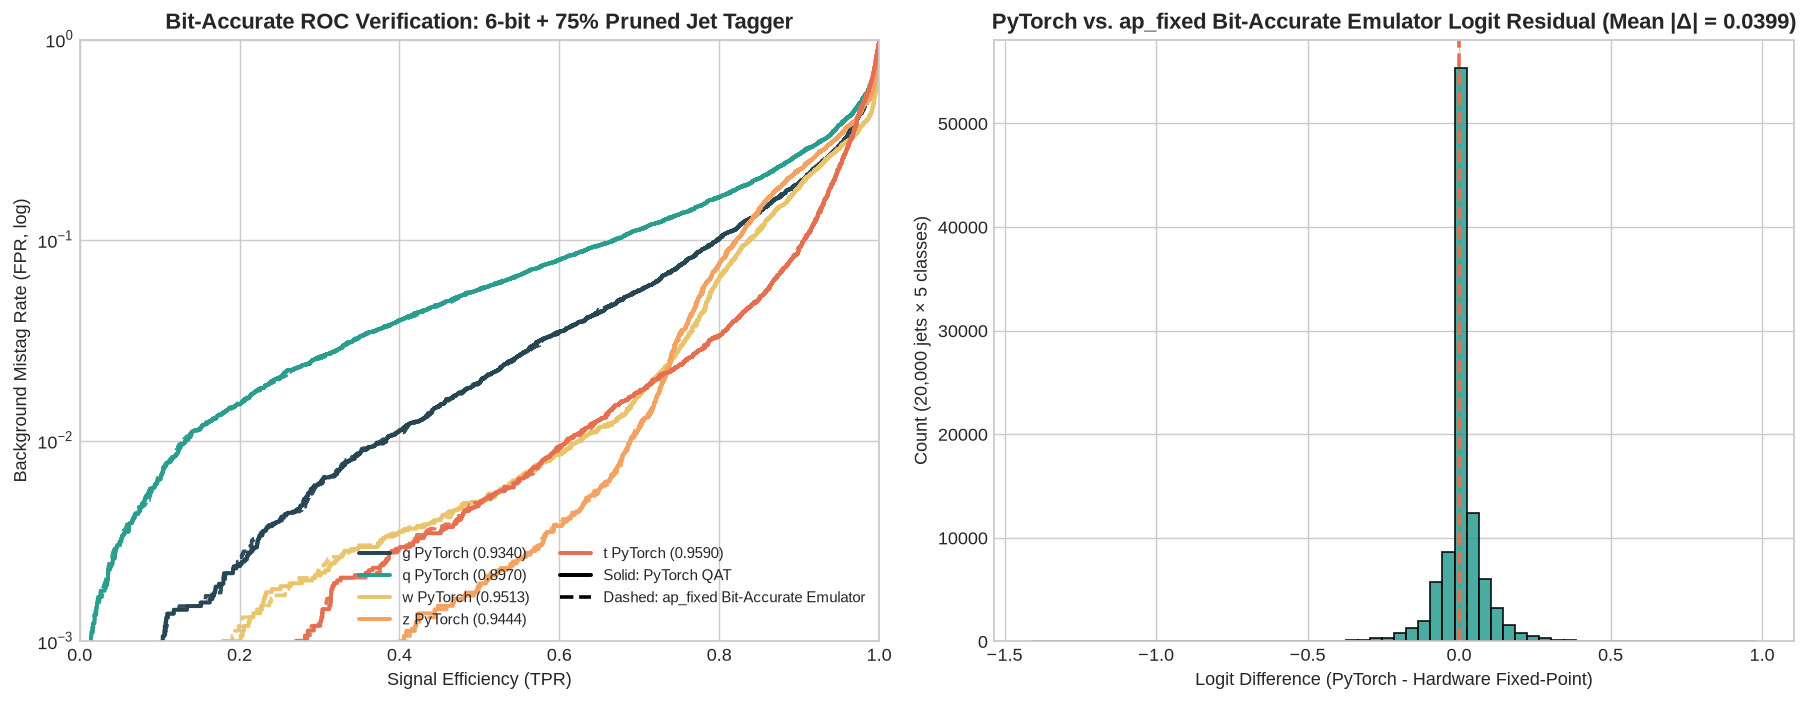

In [5]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"]

# Left: Overlaid ROC curves (Solid = PyTorch QAT 6-bit+75% pruned, Dashed = Fixed-Point Hardware)
for idx, cname in enumerate(CLASS_NAMES):
    pc_pt = m_pt_6b["per_class"][cname]
    pc_hw = m_hw_6b["per_class"][cname]
    axes[0].plot(pc_pt["tpr"], np.clip(pc_pt["fpr"], 1e-4, 1.0), color=colors[idx], linewidth=2.2,
                 label=f"{cname} PyTorch ({pc_pt['auc']:.4f})")
    axes[0].plot(pc_hw["tpr"], np.clip(pc_hw["fpr"], 1e-4, 1.0), color=colors[idx], linewidth=2.0,
                 linestyle="--", alpha=0.95)

# Dummy legend entry explaining solid vs dashed
axes[0].plot([], [], color="black", linewidth=2.2, label="Solid: PyTorch QAT")
axes[0].plot([], [], color="black", linewidth=2.0, linestyle="--", label=f"Dashed: {hw_mode}")
axes[0].set_yscale("log")
axes[0].set_ylim(1e-3, 1.0)
axes[0].set_xlim(0.0, 1.0)
axes[0].set_xlabel("Signal Efficiency (TPR)")
axes[0].set_ylabel("Background Mistag Rate (FPR, log)")
axes[0].set_title("Bit-Accurate ROC Verification: 6-bit + 75% Pruned Jet Tagger", fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8.5, ncol=2)

# Right: Logit parity scatter + residual histogram inset
diff_6b = (logits_pt_6b - logits_hw_6b).ravel()
axes[1].hist(diff_6b, bins=60, color="#2a9d8f", edgecolor="black", alpha=0.85)
axes[1].axvline(0.0, color="#e76f51", linestyle="--", linewidth=2)
axes[1].set_title(f"PyTorch vs. {hw_mode} Logit Residual (Mean |Δ| = {np.mean(np.abs(diff_6b)):.4f})", fontweight="bold")
axes[1].set_xlabel("Logit Difference (PyTorch - Hardware Fixed-Point)")
axes[1].set_ylabel("Count (20,000 jets × 5 classes)")

plt.tight_layout()
plt.savefig(FIG_DIR / "04_pytorch_vs_hls_verification.png", dpi=150)
plt.show()
print("Saved verification figure to figures/04_pytorch_vs_hls_verification.png")

## Stage 1 (TriggerNet Level 1) Complete — Ready to Defend Out Loud!
You can now answer every Level-1 CERN trigger question cleanly without notes:
1. **Why triggers exist:** 40 MHz collisions (~100 TB/s) → FPGAs decide in microseconds → anything dropped is gone forever.
2. **Why accuracy isn't enough:** Trigger scientists optimize **Background Rejection (`1 / FPR`)** at fixed Signal Efficiency (`50%` / `80%`).
3. **Why pruning + QAT matter on FPGAs:** Zero weights eliminate DSP multipliers during HLS compilation, while QAT with STE adapts weights to `ap_fixed<W, I>` grids so `6-bit` and `8-bit` models cut **Effective BOPs by >98%** with minimal physics loss.
4. **How `hls4ml` bridges Python → Silicon:** Converts PyTorch layers to `ap_fixed` C++ HLS (`myproject.cpp`, `defines.h`, `weights/*.txt`) and bit-accurate verification confirms nearly identical ROC curves before spending hours on FPGA synthesis.

**Next Stage → Level 2 (The Rare Differentiator): Raw 150-particle constituent jets + Deep Sets + CERN's `PQuantML`!**